# EgoEvGesture — VideoMamba-Tiny | 2× Tesla T4 | Inline Training & Resume — PyTorch RMSNorm Compatibility Fix

**All training code is visible directly in notebook cells.** No `TRAIN_SCRIPT`, generated training worker, `torchrun`, or external `.py` file.

**Parallel execution:** `torch.nn.DataParallel` runs one Python process and scatters mini-batches between both GPUs. It is **not DistributedDataParallel (DDP)**. Native DDP requires separate worker processes; using DataParallel is the trade-off that allows the entire Train + Validation + Checkpoint loop to live in one editable notebook cell. It may be slower than DDP, especially with expensive CPU event preprocessing.

**Task:** 38-class EgoEvGesture; published Heterogeneous Cleaned Split v1 (Train 2,626; Val 489). **Test is never used**. Input is an event-derived 16-frame, 224×224, 3-channel clip, using the same scientific preprocessing as the previous notebook.

**Required Kaggle Add Input:** EgoEvGesture Raw, published Heterogeneous Split Dataset, compatible VideoMamba CUDA wheels, and (for subsequent sessions) the prior output containing `checkpoint-latest.pth` **and** `checkpoint-best.pth`. Pretrained weights and pinned VideoMamba source are downloaded if not available in an attached input (enable Internet on the first run).

**Session continuation:** Save the output folder `/kaggle/working/egoev_videomamba_tiny_hetero_v1/` as a Kaggle notebook version or dataset, then add it to the *next* session. An interactive session's working directory is not shared with a fresh `Save & Run All` run.

**Compatibility:** Supports resuming compatible 1-GPU v1 or 2-GPU DDP-v2 checkpoints with unchanged data, model and effective batch size. Switching parallel backends is **not bit-for-bit reproducible**; best/latest files, weights, optimizer, scheduler and metrics are preserved.

**Compatibility fix v2:** The original DataParallel notebook may fail during the forward smoke test with `TypeError: NoneType object is not a mapping` in the old Mamba Triton RMSNorm autotuner on recent Kaggle Triton. This version substitutes only the RMSNorm execution path with a native PyTorch implementation. It retains the 24-layer VideoMamba-Tiny model structure and parameter names, but has different kernel numerics and potentially lower speed. **Test forward and backward before training; the DDP notebook is preferred for benchmark throughput.**

## 1 — Experiment settings

Change `EPOCHS_THIS_SESSION` (1 for a smoke test, 8 for a normal session). This notebook uses **two GPUs with global batch size 2 and accumulation 4**, so the effective batch size remains 8. `NUM_WORKERS=4` means four total DataLoader workers, **not** four workers per GPU. If DataLoader workers crash, reduce to 2 or 0 and rerun the setup cells.

* Check the notebook checkpoint model

In [1]:
from pathlib import Path
import torch

checkpoints = list(Path("/kaggle/input").rglob("checkpoint-latest.pth"))

print("Found checkpoints:", len(checkpoints))

for p in checkpoints:
    print("Path:", p)
    ckpt = torch.load(p, map_location="cpu", weights_only=False)
    print("Completed epoch:", ckpt["epoch"] + 1)
    print("Next epoch:", ckpt["epoch"] + 2)

Found checkpoints: 1
Path: /kaggle/input/notebooks/hoanganh94/egoevgesture-videomamba-tiny/egoev_videomamba_tiny_hetero_v1/checkpoint-latest.pth
Completed epoch: 8
Next epoch: 9


In [2]:
from pathlib import Path
import os, sys, re, json, math, time, copy, random, hashlib, shutil, subprocess, tempfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch

# =============== Experiment ===============
SEED = 42
NUM_CLASSES = 38
NUM_FRAMES = 16
INPUT_SIZE = 224
MAX_EVENTS_PER_SAMPLE = 200_000  # Uniformly sample event indices to approximately preserve temporal coverage
RAW_WIDTH, RAW_HEIGHT = 1280, 720

TOTAL_EPOCHS = 60
EPOCHS_THIS_SESSION = 8          # Maximum epochs IN THIS SESSION (does not reset the total)
MAX_SESSION_MINUTES = 450       # Check AFTER each epoch; a process killed mid-epoch cannot be recovered
BATCH_SIZE = 2                  # Global batch: DataParallel scatters one sample to each T4
ACCUM_STEPS = 4                # Global 2 * accumulation 4 = effective batch size 8
NUM_WORKERS = 4                 # Total workers (shared by both GPUs); use 2 if memory-constrained
BASE_LR = 1e-4
MIN_LR = 1e-6
WARMUP_EPOCHS = 3
WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0
DROP_PATH = 0.1
FC_DROP_RATE = 0.3
USE_AMP = False                 # FP32 as in the CTP baseline; enable AMP only after validating wheels and kernels
USE_GRAD_CHECKPOINT = False    # May enable before the first session if CUDA OOM occurs; do not change on resume
CHECKPOINT_LAYERS = 12

RUN_NAME = 'egoev_videomamba_tiny_hetero_v1'
OUT_DIR = Path('/kaggle/working') / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_ROOT_HINT = '/kaggle/input/datasets/hoanganh94/egoevgesture-raw'
SPLIT_ROOT_HINT = ''            # Leave blank to discover split_manifest.json automatically
RESUME_CHECKPOINT_HINT = ''    # Leave blank to discover checkpoint-latest.pth in Kaggle Input
PRETRAIN_CHECKPOINT_HINT = ''  # Leave blank to discover or download from Hugging Face if needed
VIDEOMAMBA_SOURCE_HINT = ''    # Leave blank to clone the pinned source repository
REPO_COMMIT = '37355c26d0ae99ca2459f6d4044a5f509031a79f'
REPO_DIR = Path('/kaggle/working/VideoMamba')

if TOTAL_EPOCHS < 1 or EPOCHS_THIS_SESSION < 1: raise ValueError('Epoch count must be > 0')
if INPUT_SIZE != 224 or NUM_FRAMES != 16:
    raise ValueError('The pretrained baseline uses 224x224 and 16 frames; resizing requires positional-embedding validation.')
if WARMUP_EPOCHS >= TOTAL_EPOCHS: raise ValueError('WARMUP_EPOCHS must be smaller than TOTAL_EPOCHS')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False

print('Python:',sys.version.split()[0], '| Torch:',torch.__version__, '| CUDA:',torch.version.cuda)
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT < 2:
    raise RuntimeError(f'Two CUDA GPUs are required; found {GPU_COUNT}. Choose Kaggle GPU T4 x2.')
DEVICE_IDS = [0, 1]
for gpu_id in DEVICE_IDS:
    print(f'GPU {gpu_id}: {torch.cuda.get_device_name(gpu_id)}')
if BATCH_SIZE < len(DEVICE_IDS):
    raise ValueError('DataParallel requires global BATCH_SIZE >= number of GPUs (2).')
if BATCH_SIZE * ACCUM_STEPS != 8:
    raise ValueError('Effective batch size must remain 8 to preserve this experiment.')
print('Parallel: torch.nn.DataParallel (not DDP); total workers:', NUM_WORKERS)
print('Output:',OUT_DIR)

Python: 3.13.15 | Torch: 2.11.0+cu128 | CUDA: 12.8
GPU 0: Tesla T4
GPU 1: Tesla T4
Parallel: torch.nn.DataParallel (not DDP); total workers: 4
Output: /kaggle/working/egoev_videomamba_tiny_hetero_v1


## 2 — Discover Kaggle datasets and verify the split

Fail immediately on missing files, CSV checksum mismatches, or subjects assigned to incorrect splits. **Never use `test.csv` for model training or selection.** The published CSVs store dataset-relative paths.

In [3]:
INPUT_BASE = Path('/kaggle/input')
if not INPUT_BASE.is_dir(): raise RuntimeError('Run on Kaggle and add the raw dataset and split CSV dataset as Input.')

def find_split_root():
    if SPLIT_ROOT_HINT:
        p=Path(SPLIT_ROOT_HINT)
        if not (p/'train.csv').is_file(): raise FileNotFoundError(p/'train.csv')
        return p
    roots=[]
    for d,dirs,files in os.walk(INPUT_BASE):
        p=Path(d)
        depth=len(p.relative_to(INPUT_BASE).parts)
        if {'train.csv','val.csv','split_manifest.json'} <= set(files):
            roots.append(p)
            dirs[:]=[]
        elif depth>=6 or re.fullmatch(r'subj\d+_(left|right)',p.name):
            dirs[:]=[]
    if len(roots)!=1: raise RuntimeError('Exactly one split dataset with train.csv/val.csv/manifest is required. Found: '+str(roots))
    return roots[0]

def find_raw_root():
    p=Path(RAW_ROOT_HINT)
    if (p/'subj3_left').is_dir() and (p/'subj8_right').is_dir():return p
    roots=[]
    for d,dirs,files in os.walk(INPUT_BASE):
        p=Path(d)
        if (p/'subj3_left').is_dir() and (p/'subj8_right').is_dir():
            roots.append(p);dirs[:]=[]
        elif len(p.relative_to(INPUT_BASE).parts)>=5:dirs[:]=[]
    if len(roots)!=1: raise RuntimeError('Could not uniquely identify the raw dataset. Roots: '+str(roots))
    return roots[0]

SPLIT_ROOT=find_split_root()
RAW_ROOT=find_raw_root()
MANIFEST_PATH=SPLIT_ROOT/'split_manifest.json'
manifest=json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))

def sha256_path(path,block=8*1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(block),b''):h.update(b)
    return h.hexdigest()

assert manifest.get('schema_version')=='egoev-clean-split/1.0', 'Invalid split manifest schema'
assert manifest.get('protocol')=='heterogeneous_subject_holdout_cleaned', 'Invalid split protocol'
EXPECTED={'train':({3,4,5,6,7},2626),'val':({8},489)}
FRAMES={}
CSV_SHA={}
for name,(subjects,count) in EXPECTED.items():
    p=SPLIT_ROOT/(name+'.csv')
    if not p.is_file():raise FileNotFoundError(p)
    actual=sha256_path(p)
    expected_hash=manifest.get('csv_sha256',{}).get(p.name)
    if actual!=expected_hash: raise RuntimeError('CSV was modified or does not match the manifest: '+p.name)
    df=pd.read_csv(p)
    need={'relative_path','gesture_id','subject','size_bytes'}
    if not need.issubset(df.columns):raise RuntimeError(f'{name}: missing columns {need-set(df.columns)}')
    if len(df)!=count or set(df.subject.astype(int))!=subjects:raise RuntimeError(f'{name}: invalid count/subjects')
    if set(df.gesture_id.astype(int)) != set(range(38)):raise RuntimeError(f'{name}: missing classes')
    if not df.relative_path.is_unique:raise RuntimeError(f'{name}: duplicate paths')
    if df.gesture_id.isna().any():raise RuntimeError(f'{name}: null label')
    for row in df.itertuples(index=False):
        rel=Path(row.relative_path)
        if rel.is_absolute() or '..' in rel.parts:raise RuntimeError(f'Unsafe relative path: {rel}')
        f=RAW_ROOT/rel
        if not f.is_file() or f.stat().st_size!=int(row.size_bytes):
            raise RuntimeError(f'Sample missing or file size differs from CSV: {f}')
        m=re.fullmatch(r'act(\d+)_(\d+)\.npy',f.name)
        if not m or int(m.group(1))%38!=int(row.gesture_id):raise RuntimeError(f'invalid label: {rel}')
    FRAMES[name]=df
    CSV_SHA[name]=actual
    print(f'{name}: {len(df)} samples, {df.gesture_id.nunique()} classes, subjects={sorted(subjects)} | SHA256={actual[:16]}...')

if set(FRAMES['train'].relative_path)&set(FRAMES['val'].relative_path):
    raise RuntimeError('Train/validation path leakage')
print('RAW_ROOT =',RAW_ROOT)
print('SPLIT_ROOT =',SPLIT_ROOT)
print('SPLIT PREFLIGHT: PASS (Test has not been read or used)')

train: 2626 samples, 38 classes, subjects=[3, 4, 5, 6, 7] | SHA256=45a7bcac2ebb213c...
val: 489 samples, 38 classes, subjects=[8] | SHA256=03c3053b6e4cca52...
RAW_ROOT = /kaggle/input/datasets/hoanganh94/egoevgesture-raw
SPLIT_ROOT = /kaggle/input/datasets/hoanganh94/egoevgesture-heterogeneous-split-dataset/egoev_heterogeneous_split_v1
SPLIT PREFLIGHT: PASS (Test has not been read or used)


## 3 — Dataset fingerprints and checkpoint discovery

The notebook uses the published CSVs as a fixed data protocol. Resuming requires identical scientific settings and effective batch size. Parallel implementation metadata (DDP versus DataParallel) may differ; that change is explicitly reported.

In [4]:
IMMUTABLE_CONFIG = {
    'model':'videomamba_tiny', 'num_classes':NUM_CLASSES,
    'num_frames':NUM_FRAMES, 'input_size':INPUT_SIZE, 'max_events':MAX_EVENTS_PER_SAMPLE,
    'sensor_width':RAW_WIDTH,'sensor_height':RAW_HEIGHT,
    'train_csv_sha256':CSV_SHA['train'],'val_csv_sha256':CSV_SHA['val'],
    'seed':SEED,'batch_size':BATCH_SIZE,'accum_steps':ACCUM_STEPS,
    'effective_batch_size':BATCH_SIZE*ACCUM_STEPS,
    'world_size':len(DEVICE_IDS),'distributed_backend':'dataparallel',
    'total_epochs':TOTAL_EPOCHS,'base_lr':BASE_LR,'min_lr':MIN_LR,
    'warmup_epochs':WARMUP_EPOCHS,'weight_decay':WEIGHT_DECAY,
    'grad_clip':GRAD_CLIP,'drop_path':DROP_PATH,'fc_drop_rate':FC_DROP_RATE,
    'use_amp':USE_AMP,'grad_checkpoint':USE_GRAD_CHECKPOINT,
    'checkpoint_layers':CHECKPOINT_LAYERS if USE_GRAD_CHECKPOINT else 0,
    'repo_commit':REPO_COMMIT,
    'event_channels':'positive_count,negative_count,total_count',
    'normalization':'log1p + clip_to_99pct_nonzero + imagenet_rgb_norm',
    'sampling':'linspace_event_index_deterministic',
}
CONFIG_FILE=OUT_DIR/'experiment_config.json'
CONFIG_FILE.write_text(json.dumps(IMMUTABLE_CONFIG,indent=2,ensure_ascii=False),encoding='utf-8')

def locate_resume():
    if RESUME_CHECKPOINT_HINT:
        p=Path(RESUME_CHECKPOINT_HINT)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    candidates=[]
    for root,dirs,files in os.walk(INPUT_BASE):
        p=Path(root)
        if 'checkpoint-latest.pth' in files:
            candidates.append(p/'checkpoint-latest.pth')
            dirs[:]=[]
        elif len(p.relative_to(INPUT_BASE).parts)>=8 or re.fullmatch(r'subj\d+_(left|right)',p.name):
            dirs[:]=[]
    if len(candidates)>1:
        raise RuntimeError('Multiple checkpoint-latest.pth files found; set RESUME_CHECKPOINT_HINT:\n'+'\n'.join(map(str,candidates)))
    return candidates[0] if candidates else None

RESUME_PATH=locate_resume()
if RESUME_PATH:
    print('RESUME checkpoint found:',RESUME_PATH)
    if not (RESUME_PATH.parent/'checkpoint-best.pth').is_file():
        raise FileNotFoundError('Previous session is missing checkpoint-best.pth: '+str(RESUME_PATH.parent))
else:
    print('No resume checkpoint found: initialize from pretrained VideoMamba-Tiny.')

RESUME checkpoint found: /kaggle/input/notebooks/hoanganh94/egoevgesture-videomamba-tiny/egoev_videomamba_tiny_hetero_v1/checkpoint-latest.pth


## 4 — Official VideoMamba source and CUDA extension wheels

Use the **OpenGVLab/VideoMamba repository pinned to the same commit as the earlier CTPGesture notebook**. Wheels for `mamba_ssm` and `causal_conv1d` must match the exact **Python ABI, PyTorch, CUDA, and GPU architecture**. This cell does not attempt to build CUDA extensions. If the Kaggle runtime uses Python 3.13 but only `cp312` wheels are available, supply compatible wheels or use a matching runtime. **Do not silently substitute a different model architecture.**

In [5]:
if not torch.cuda.is_available():
    raise RuntimeError('GPU not enabled: Kaggle Notebook Settings → Accelerator → GPU T4.')

import importlib, importlib.util, importlib.metadata, sysconfig
from packaging.tags import sys_tags
from packaging.utils import parse_wheel_filename

# If the modules are already installed and importable, wheels are not required.
def cuda_import_ready():
    try:
        from causal_conv1d import causal_conv1d_fn
        from mamba_ssm.modules.mamba_simple import Mamba
        import causal_conv1d_cuda, selective_scan_cuda
        import inspect
        if 'bimamba' not in inspect.signature(Mamba.__init__).parameters:
            raise RuntimeError('mamba_ssm lacks bimamba=True support and is incompatible with this VideoMamba commit.')
        return True
    except Exception as e:
        print('CUDA extension unavailable:',type(e).__name__,str(e)[:400])
        return False

def run_cmd(args, cwd=None):
    print('$',' '.join(map(str,args)),flush=True)
    subprocess.run(list(map(str,args)),cwd=str(cwd) if cwd else None,check=True)

# Install PyPI dependencies during setup; add prebuilt CUDA wheels as Input.
def installed_version(name):
    try:return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:return None
if installed_version('timm')!='0.4.12' or installed_version('transformers')!='4.36.1' or not importlib.util.find_spec('einops'):
    run_cmd([sys.executable,'-m','pip','install','-q','--upgrade','timm==0.4.12','transformers==4.36.1','einops','packaging'])

if not cuda_import_ready():
    compatible_tags=set(sys_tags())
    wheels=[]
    for root,dirs,files in os.walk(INPUT_BASE):
        p=Path(root)
        for filename in files:
            if filename.endswith('.whl') and (filename.lower().startswith('mamba_ssm-') or filename.lower().startswith('causal_conv1d-')):
                f=p/filename
                try:
                    dist,vers,build,tags=parse_wheel_filename(filename)
                    if tags & compatible_tags:
                        wheels.append((str(dist).replace('-','_').lower(),f))
                except Exception as exc:print('Invalid wheel filename:',filename,exc)
        if len(p.relative_to(INPUT_BASE).parts)>=6 or re.fullmatch(r'subj\d+_(left|right)',p.name):
            dirs[:]=[]
    selection={}
    for package in ('causal_conv1d','mamba_ssm'):
        matches=[f for kind,f in wheels if kind==package]
        if len(matches)!=1:
            raise RuntimeError(f'{package}: found {len(matches)} wheels matching the Python ABI in Kaggle Input. '
                               f'Add a wheel dataset compatible with this runtime ({sys.version.split()[0]}, torch {torch.__version__}, CUDA {torch.version.cuda}); '
                               f'available wheels: {[str(f) for f in matches]}')
        selection[package]=matches[0]
    run_cmd([sys.executable,'-m','pip','install','-q','--no-deps',str(selection['causal_conv1d'])])
    run_cmd([sys.executable,'-m','pip','install','-q','--no-deps',str(selection['mamba_ssm'])])
    importlib.invalidate_caches()
    if not cuda_import_ready():
        raise RuntimeError('Wheels installed but CUDA import failed. Check PyTorch/CUDA/ABI compatibility; training will not continue.')

if VIDEOMAMBA_SOURCE_HINT:
    REPO_DIR=Path(VIDEOMAMBA_SOURCE_HINT)
    if not (REPO_DIR/'videomamba/video_sm/models/videomamba.py').is_file():
        raise FileNotFoundError('VIDEOMAMBA_SOURCE_HINT does not point to the required VideoMamba repository')
else:
    if not (REPO_DIR/'.git').is_dir():
        run_cmd(['git','clone','https://github.com/OpenGVLab/VideoMamba.git',str(REPO_DIR)])
    run_cmd(['git','-C',str(REPO_DIR),'checkout','--detach',REPO_COMMIT])
    revision=subprocess.check_output(['git','-C',str(REPO_DIR),'rev-parse','HEAD'],text=True).strip()
    if revision!=REPO_COMMIT:raise RuntimeError('Repository revision sai')

VIDEO_SM_DIR=REPO_DIR/'videomamba/video_sm'
if str(VIDEO_SM_DIR) not in sys.path:sys.path.insert(0,str(VIDEO_SM_DIR))
from models.videomamba import videomamba_tiny

# ------------------------------------------------------------
# Triton RMSNorm fallback for inline two-GPU DataParallel.
# This is an EXECUTION-BACKEND workaround, not a model redesign.
# It avoids the legacy Triton autotuner being entered concurrently
# by multiple DataParallel replica threads.
# ------------------------------------------------------------
import models.videomamba as videomamba_module
import mamba_ssm.ops.triton.layernorm as legacy_layernorm

NORM_EXECUTION_BACKEND = 'torch_native_rmsnorm_fp32_v1'

def _dp_safe_rms_norm_fn(
    x, weight, bias, residual=None, prenorm=False,
    residual_in_fp32=False, eps=1e-6
):
    # The configured experiment runs FP32. Keep the original RMSNorm
    # trainable weights, eps, and prenorm/residual semantics.
    residual_sum = x if residual is None else x + residual
    residual_out = residual_sum.float() if residual_in_fp32 else residual_sum
    z = residual_sum.float()
    z = z * torch.rsqrt(z.square().mean(dim=-1, keepdim=True) + eps)
    z = z * weight.float()
    if bias is not None:
        z = z + bias.float()
    z = z.to(dtype=x.dtype)
    return (z, residual_out) if prenorm else z

# VideoMamba imports rms_norm_fn as a module-global reference.
# Patching only the library symbol would not redirect the Block calls.
videomamba_module.rms_norm_fn = _dp_safe_rms_norm_fn
legacy_layernorm.rms_norm_fn = _dp_safe_rms_norm_fn

# Also replace the rarely used direct RMSNorm.forward path.
def _dp_safe_rmsnorm_forward(
    self, x, residual=None, prenorm=False, residual_in_fp32=False
):
    return _dp_safe_rms_norm_fn(
        x, self.weight, self.bias, residual=residual, prenorm=prenorm,
        residual_in_fp32=residual_in_fp32, eps=self.eps
    )
legacy_layernorm.RMSNorm.forward = _dp_safe_rmsnorm_forward

print('[COMPATIBILITY] Native PyTorch RMSNorm activated for 2-GPU DataParallel.')

print('VIDEO MAMBA IMPORT: PASS',VIDEO_SM_DIR)

$ /usr/bin/python3 -m pip install -q --upgrade timm==0.4.12 transformers==4.36.1 einops packaging
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 40.3 MB/s eta 0:00:00
CUDA extension unavailable: ModuleNotFoundError No module named 'causal_conv1d'
$ /usr/bin/python3 -m pip install -q --no-deps /kaggle/input/datasets/hoanganh94/kaggle-cuda-wheel-latest-version/videomamba_cuda_wheels/causal_conv1d-1.0.0+vm37355c26.cu128.torch2110.abi1.sm75-cp313-cp313-linux_x86_64.whl


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.85.7 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.15.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.1 which is incompatible.


$ /usr/bin/python3 -m pip install -q --no-deps /kaggle/input/datasets/hoanganh94/kaggle-cuda-wheel-latest-version/videomamba_cuda_wheels/mamba_ssm-1.0.1+vm37355c26.cu128.torch2110.abi1.sm75-cp313-cp313-linux_x86_64.whl


/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:227: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:295: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:368: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.13/dist-packages/

$ git clone https://github.com/OpenGVLab/VideoMamba.git /kaggle/working/VideoMamba


/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
Cloning into '/kaggle/working/VideoMamba'...


$ git -C /kaggle/working/VideoMamba checkout --detach 37355c26d0ae99ca2459f6d4044a5f509031a79f


HEAD is now at 37355c2 Update MODEL_ZOO.md


[COMPATIBILITY] Native PyTorch RMSNorm activated for 2-GPU DataParallel.
VIDEO MAMBA IMPORT: PASS /kaggle/working/VideoMamba/videomamba/video_sm


## 5 — Event preprocessing and DataLoader (CPU)

The same deterministic 16-frame event representation is used in both the previous single-GPU and DDP notebooks. `NUM_WORKERS` is the **total** number of workers on this process. To reduce Kaggle shared-memory pressure, we use `prefetch_factor=1` and `persistent_workers=False`.

In [6]:
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEAN=np.array([0.485,0.456,0.406],dtype=np.float32)[:,None,None,None]
IMAGENET_STD=np.array([0.229,0.224,0.225],dtype=np.float32)[:,None,None,None]

def events_to_clip(events, *, num_frames=NUM_FRAMES, out_size=INPUT_SIZE, max_events=MAX_EVENTS_PER_SAMPLE):
    if events.ndim != 2 or events.shape[1]!=4 or len(events)<2:
        raise ValueError(f'Expected event Nx4, >=2 events, got {events.shape}')
    n=len(events)
    idx=np.linspace(0,n-1,min(n,max_events),dtype=np.int64)
    subset=np.asarray(events[idx],dtype=np.float64)
    x,y,p,t=subset.T
    if not (np.isfinite(subset).all()):raise ValueError('NaN/Inf event')
    if not (np.all((0<=x)&(x<RAW_WIDTH)) and np.all((0<=y)&(y<RAW_HEIGHT))):
        raise ValueError('Coordinates outside 1280×720. Check Nx4 column order/sensor geometry.')
    if not (t[-1]>t[0]):raise ValueError('Event timestamps do not span positive time')
    pol=set(np.unique(p).tolist())
    if not pol.issubset({-1.0,0.0,1.0}):raise ValueError(f'Polarity unexpected: {pol}')

    # uniform TIME bins, not equal-event bins
    k=np.floor((t-t[0]) / (t[-1]-t[0]) * num_frames).astype(np.int32)
    k=np.clip(k,0,num_frames-1)
    scale=out_size/max(RAW_WIDTH,RAW_HEIGHT)
    scaled_w=int(round(RAW_WIDTH*scale));scaled_h=int(round(RAW_HEIGHT*scale))
    ox=(out_size-scaled_w)//2;oy=(out_size-scaled_h)//2
    xx=np.clip(np.floor(x*scale).astype(np.int32)+ox,0,out_size-1)
    yy=np.clip(np.floor(y*scale).astype(np.int32)+oy,0,out_size-1)
    pos=(p>0)
    linear=k*(out_size*out_size)+yy*out_size+xx
    bins=num_frames*out_size*out_size
    pos_count=np.bincount(linear[pos],minlength=bins).reshape(num_frames,out_size,out_size)
    neg_count=np.bincount(linear[~pos],minlength=bins).reshape(num_frames,out_size,out_size)
    total=pos_count+neg_count
    clip=np.stack([pos_count,neg_count,total],axis=0).astype(np.float32)
    np.log1p(clip,out=clip)
    nonzero=clip[clip>0]
    denom=float(np.percentile(nonzero,99.0)) if len(nonzero) else 1.0
    clip=np.clip(clip/max(denom,1e-6),0,1)
    clip=(clip-IMAGENET_MEAN)/IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(clip))  # [C,T,H,W]

class EgoEvDataset(Dataset):
    def __init__(self, df,root):
        self.rows=df[['relative_path','gesture_id']].to_records(index=False)
        self.root=Path(root)
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        rel,label=self.rows[i]
        p=self.root/str(rel)
        events=np.load(p,mmap_mode='r',allow_pickle=False)
        frames=events_to_clip(events)
        if not torch.isfinite(frames).all():raise ValueError(f'NaN frame: {p}')
        return frames,int(label)

train_dataset=EgoEvDataset(FRAMES['train'],RAW_ROOT)
val_dataset=EgoEvDataset(FRAMES['val'],RAW_ROOT)
for label,ds in [('TRAIN',train_dataset),('VAL',val_dataset)]:
    x,y=ds[0]
    assert x.shape==(3,NUM_FRAMES,INPUT_SIZE,INPUT_SIZE)
    assert 0<=y<NUM_CLASSES
    print(label, '| samples',len(ds),'| example',tuple(x.shape),'| label',y,
          '| tensor min/max',round(float(x.min()),3),round(float(x.max()),3))

def seed_worker(worker_id):
    seed=torch.initial_seed()%2**32
    np.random.seed(seed);random.seed(seed)

loader_kwargs = dict(
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=False,
    worker_init_fn=seed_worker,
)
if NUM_WORKERS > 0:
    loader_kwargs['prefetch_factor'] = 1
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
print(f'DataLoaders: global batch={BATCH_SIZE}, workers={NUM_WORKERS}, '
      f'train_batches={len(train_loader)}, val_batches={len(val_loader)}')
print('EVENT DATALOADER: PASS')

TRAIN | samples 2626 | example (3, 16, 224, 224) | label 0 | tensor min/max -2.118 2.64
VAL | samples 489 | example (3, 16, 224, 224) | label 2 | tensor min/max -2.118 2.64
DataLoaders: global batch=2, workers=4, train_batches=1313, val_batches=245
EVENT DATALOADER: PASS


## 6 — VideoMamba-Tiny, model parallelization and checkpoint resume

Pretrained backbone: original pinned VideoMamba-Tiny weights. During resume, restore model weights (without any `module.` prefix), optimizer, scheduler, history and the previous **best** checkpoint. `DataParallel` replicates the model across both GPUs during forward; checkpoints always save the underlying `base_model` for portability.

In [7]:
from torch import nn
from urllib.request import urlretrieve

PRETRAIN_NAME='videomamba_t16_in1k_res224.pth'
PRETRAIN_URL='https://huggingface.co/OpenGVLab/VideoMamba/resolve/main/'+PRETRAIN_NAME

def locate_pretrained():
    if PRETRAIN_CHECKPOINT_HINT:
        p=Path(PRETRAIN_CHECKPOINT_HINT)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    candidates=[]
    for root,dirs,files in os.walk(INPUT_BASE):
        if PRETRAIN_NAME in files: candidates.append(Path(root)/PRETRAIN_NAME)
        p=Path(root)
        if len(p.relative_to(INPUT_BASE).parts)>=7 or re.fullmatch(r'subj\d+_(left|right)',p.name):dirs[:]=[]
    if len(candidates)>1:raise RuntimeError('Multiple pretrained weight files found; set PRETRAIN_CHECKPOINT_HINT: '+str(candidates))
    if candidates:return candidates[0]
    path=OUT_DIR/PRETRAIN_NAME
    if not path.is_file() or path.stat().st_size<10_000_000:
        print('Downloading pretrained model ...')
        try:urlretrieve(PRETRAIN_URL,path)
        except Exception as exc:raise RuntimeError('Could not download pretrained weights. Enable Internet or add pretrained weights as Input.') from exc
    return path

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

def make_model():
    return videomamba_tiny(pretrained=False,num_classes=NUM_CLASSES,num_frames=NUM_FRAMES,
                           img_size=INPUT_SIZE,drop_path_rate=DROP_PATH,fc_drop_rate=FC_DROP_RATE,
                           use_checkpoint=USE_GRAD_CHECKPOINT,
                           checkpoint_num=CHECKPOINT_LAYERS if USE_GRAD_CHECKPOINT else 0)

def load_pretrained(model,path):
    ckpt=safe_load(path)
    weights=ckpt.get('model',ckpt.get('state_dict',ckpt))
    if not isinstance(weights,dict):raise RuntimeError('Pretrained checkpoint missing model weights')
    weights={k.removeprefix('module.').removeprefix('backbone.'):v for k,v in weights.items()}
    weights={k:v for k,v in weights.items() if k not in ('head.weight','head.bias')}
    if weights.get('patch_embed.proj.weight') is not None and weights['patch_embed.proj.weight'].ndim==4:
        weights['patch_embed.proj.weight']=weights['patch_embed.proj.weight'].unsqueeze(2)
    target=model.state_dict()
    if 'temporal_pos_embedding' in weights:
        t=weights['temporal_pos_embedding']
        if t.shape!=target['temporal_pos_embedding'].shape:
            weights['temporal_pos_embedding']=F.interpolate(
                t.permute(0,2,1).float(),size=NUM_FRAMES,mode='linear',align_corners=False).permute(0,2,1)
    valid={k:v for k,v in weights.items() if k in target and v.shape==target[k].shape}
    loaded_parameters=sum(v.numel() for v in valid.values())
    all_backbone_parameters=sum(v.numel() for k,v in target.items() if not k.startswith('head.'))
    ratio=loaded_parameters/all_backbone_parameters
    if ratio<0.90:raise RuntimeError(f'Too few compatible pretrained parameters ({ratio:.1%}), aborting')
    ret=model.load_state_dict(valid,strict=False)
    print(f'Loaded pretrained backbone {ratio:.1%}, params={loaded_parameters:,}, '
          f'missing keys={ret.missing_keys[:12]}',flush=True)

base_model = make_model()
if RESUME_PATH is None:
    pretrained_path = locate_pretrained()
    if pretrained_path.stat().st_size < 10_000_000:
        raise RuntimeError('Pretrained weights too small or invalid')
    load_pretrained(base_model, pretrained_path)
else:
    pretrained_path = None

DEVICE = torch.device('cuda:0')
base_model = base_model.to(DEVICE)
# Both GPUs are used in each forward pass. This is DP, not DDP.
model = torch.nn.DataParallel(base_model, device_ids=DEVICE_IDS, output_device=0)
optimizer = torch.optim.AdamW(base_model.parameters(), lr=BASE_LR,
                              weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999))

def lr_factor(epoch):
    if epoch < WARMUP_EPOCHS:
        return float(epoch + 1) / max(1, WARMUP_EPOCHS)
    progress = (epoch - WARMUP_EPOCHS) / max(1, TOTAL_EPOCHS - WARMUP_EPOCHS - 1)
    return MIN_LR / BASE_LR + (1 - MIN_LR / BASE_LR) * 0.5 * (
        1 + math.cos(math.pi * min(progress, 1.0)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_factor)
try:
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

start_epoch = 0
best_acc = -1.0
best_val_loss = float('inf')
history = []

TECHNICAL_CONFIG_KEYS = {
    'batch_size', 'accum_steps', 'effective_batch_size',
    'world_size', 'distributed_backend', 'parallel_mode', 'ddp'
}

def effective_batch_of(config):
    if 'effective_batch_size' in config:
        return int(config['effective_batch_size'])
    return (int(config['batch_size']) * int(config['accum_steps']) *
            int(config.get('world_size', 1)))

def check_resume_compat(checkpoint):
    previous = checkpoint.get('immutable_config')
    if not isinstance(previous, dict):
        raise RuntimeError('Resume checkpoint is missing immutable_config')
    if effective_batch_of(previous) != BATCH_SIZE * ACCUM_STEPS:
        raise RuntimeError('Effective batch size changed; resume rejected.')
    differences = {
        key: (previous.get(key), value)
        for key, value in IMMUTABLE_CONFIG.items()
        if key not in TECHNICAL_CONFIG_KEYS and previous.get(key) != value
    }
    if differences:
        raise RuntimeError('Scientific settings or split CSV mismatch: ' + str(differences))
    old_mode = previous.get('distributed_backend', 'single_gpu')
    if old_mode != 'dataparallel':
        print(f'[RESUME WARNING] Changing parallel mode from {old_mode} to DataParallel. '
              'Optimizer is restored, but training is not bitwise identical.', flush=True)

def restore_rng(checkpoint):
    rng = checkpoint.get('rng')
    if rng is None and checkpoint.get('rng_by_rank'):
        rng = checkpoint['rng_by_rank'][0]
    if not rng:
        return
    random.setstate(rng['python'])
    np.random.set_state(rng['numpy'])
    torch.set_rng_state(rng['torch_cpu'])
    cuda_rng = rng.get('torch_cuda')
    if cuda_rng is not None and torch.cuda.is_available():
        if isinstance(cuda_rng, (tuple, list)) and len(cuda_rng) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(cuda_rng)
        elif isinstance(cuda_rng, (tuple, list)) and len(cuda_rng):
            torch.cuda.set_rng_state(cuda_rng[0], device=DEVICE)
        elif not isinstance(cuda_rng, (tuple, list)):
            torch.cuda.set_rng_state(cuda_rng, device=DEVICE)

if RESUME_PATH is not None:
    checkpoint = safe_load(RESUME_PATH)
    check_resume_compat(checkpoint)
    # DDP, single-GPU and DP checkpoints store unwrapped model weights.
    base_model.load_state_dict(checkpoint['model'], strict=True)
    optimizer.load_state_dict(checkpoint['optimizer'])
    scheduler.load_state_dict(checkpoint['scheduler'])
    if USE_AMP and checkpoint.get('scaler') is not None:
        scaler.load_state_dict(checkpoint['scaler'])
    start_epoch = int(checkpoint['epoch']) + 1
    best_acc = float(checkpoint['best_val_acc'])
    best_val_loss = float(checkpoint.get('best_val_loss', float('inf')))
    history = list(checkpoint.get('history', []))
    best_input_path = RESUME_PATH.parent / 'checkpoint-best.pth'
    best_previous = safe_load(best_input_path)
    check_resume_compat(best_previous)
    if int(best_previous['epoch']) > int(checkpoint['epoch']):
        raise RuntimeError('Best checkpoint is newer than latest checkpoint')
    shutil.copy2(best_input_path, OUT_DIR / 'checkpoint-best.pth')
    # Restore RNG after model and optimizer initialization.
    restore_rng(checkpoint)
    print(f'[RESUME PASS] Previous epochs: {start_epoch}; best={best_acc:.2%}', flush=True)
else:
    print('[INITIALIZATION] First session: ImageNet-pretrained backbone.', flush=True)

if start_epoch > TOTAL_EPOCHS:
    raise RuntimeError('Checkpoint epoch exceeds TOTAL_EPOCHS')
print('Model parameters:', sum(p.numel() for p in base_model.parameters()))
print('Parallel mode: DataParallel; GPUs:', DEVICE_IDS,
      '| global batch:', BATCH_SIZE, '| effective batch:', BATCH_SIZE * ACCUM_STEPS)
print('Current LR:', optimizer.param_groups[0]['lr'])


Use checkpoint: False
Checkpoint number: 0
[RESUME PASS] Previous epochs: 8; best=66.67%
Model parameters: 6965414
Parallel mode: DataParallel; GPUs: [0, 1] | global batch: 2 | effective batch: 8
Current LR: 9.806540743628244e-05


## 7 — Two-GPU forward AND backward smoke test

This test runs **both forward and backward on the two T4 GPUs**, before the training loop. It verifies that the native RMSNorm fallback avoids the previous Triton error in both directions. It restores the Python, NumPy, and PyTorch random-number-generator states afterwards and clears test gradients. An import-only test is insufficient.

In [8]:
# Smoke test: exercise DataParallel on BOTH GPUs, including gradients.
# IMPORTANT: RUN THIS CELL BEFORE THE TRAIN CELL.
model.train()
_rng_py = random.getstate()
_rng_np = np.random.get_state()
_rng_torch = torch.get_rng_state()
_rng_cuda = torch.cuda.get_rng_state_all()
try:
    xb, yb = next(iter(val_loader))
    if xb.shape[0] < 2:
        raise RuntimeError('Two-GPU DataParallel smoke test requires >=2 samples.')
    xb = xb.to(DEVICE, non_blocking=True)
    yb = yb.to(DEVICE, non_blocking=True)
    logits = model(xb)
    assert logits.shape == (xb.shape[0], NUM_CLASSES), logits.shape
    assert torch.isfinite(logits).all()
    test_loss = F.cross_entropy(logits, yb)
    test_loss.backward()
    assert any(p.grad is not None for p in base_model.parameters())
    print('TWO-GPU FORWARD + BACKWARD: PASS', tuple(logits.shape),
          '| loss=', round(test_loss.item(), 5),
          '| norm_backend=', NORM_EXECUTION_BACKEND, flush=True)
finally:
    optimizer.zero_grad(set_to_none=True)
    model.eval()
    random.setstate(_rng_py)
    np.random.set_state(_rng_np)
    torch.set_rng_state(_rng_torch)
    torch.cuda.set_rng_state_all(_rng_cuda)
    torch.cuda.empty_cache()


TWO-GPU FORWARD + BACKWARD: PASS (2, 38) | loss= 0.03183 | norm_backend= torch_native_rmsnorm_fp32_v1


## 8 — TRAIN (single editable notebook cell)

**All executable Train, Validation, ASCII progress logging, checkpoint saving and epoch control live below.** No `TRAIN_SCRIPT`, `torchrun` or generated `.py` files. `DataParallel` uses both GPUs but may have different performance characteristics from DDP. Keep `test.csv` untouched.

Each finished epoch saves `checkpoint-latest.pth`; improved validation accuracy also updates `checkpoint-best.pth`. The current session stops after at most `EPOCHS_THIS_SESSION` additional epochs. To recover across sessions, save outputs durably and Add Input again.

The RMSNorm fallback keeps the same trainable VideoMamba-Tiny parameters, but uses PyTorch operators rather than the legacy Mamba Triton kernel. Its floating-point results and performance can differ slightly from the DDP baseline. Only consider the run validated once the forward/backward smoke test passes.

In [9]:

import os
import math
import time
import random
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F

from datetime import datetime, timezone
from contextlib import nullcontext
from sklearn.metrics import f1_score, balanced_accuracy_score


# ============================================================
# 1. LOGGING CONFIGURATION
# ============================================================

PROGRESS_BAR_WIDTH = 24

# Approximately 20 progress updates per training epoch.
TRAIN_LOG_UPDATES = 20

# Approximately 5 progress updates during validation.
VAL_LOG_UPDATES = 5


def format_duration(seconds):
    seconds = max(0, int(seconds))

    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)

    if hours:
        return f"{hours:02d}h:{minutes:02d}m:{seconds:02d}s"

    if minutes:
        return f"{minutes:02d}m:{seconds:02d}s"

    return f"{seconds:02d}s"


def progress_bar(current, total, width=PROGRESS_BAR_WIDTH):
    ratio = current / max(total, 1)
    filled = min(width, int(ratio * width))

    return (
        "[" + "#" * filled + "-" * (width - filled) + "]"
    )


def gpu_memory_info():
    if not torch.cuda.is_available():
        return "GPU=N/A"

    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)
    peak = torch.cuda.max_memory_allocated() / (1024 ** 3)

    return (
        f"VRAM={allocated:.2f}GB "
        f"reserved={reserved:.2f}GB "
        f"peak={peak:.2f}GB"
    )


def print_progress(
    phase,
    epoch,
    step,
    total_steps,
    samples,
    start_time,
    loss,
    accuracy=None
):
    elapsed = time.monotonic() - start_time

    percentage = 100.0 * step / max(total_steps, 1)

    remaining_steps = total_steps - step
    seconds_per_step = elapsed / max(step, 1)
    eta_seconds = remaining_steps * seconds_per_step

    throughput = samples / max(elapsed, 1e-6)

    bar = progress_bar(step, total_steps)

    message = (
        f"[{phase}] "
        f"Epoch {epoch + 1:03d}/{TOTAL_EPOCHS:03d} "
        f"{bar} "
        f"{percentage:5.1f}% "
        f"({step}/{total_steps}) "
        f"| loss={loss:.4f}"
    )

    if accuracy is not None:
        message += f" | acc={accuracy:.2%}"

    message += (
        f" | speed={throughput:.2f} samples/s"
        f" | elapsed={format_duration(elapsed)}"
        f" | ETA={format_duration(eta_seconds)}"
    )

    message += f" | {gpu_memory_info()}"

    # Newline-based logging, compatible with Kaggle Background Logs.
    print(message, flush=True)


def autocast_context():
    return (
        torch.autocast(device_type="cuda", dtype=torch.float16)
        if USE_AMP
        else nullcontext()
    )


# ============================================================
# 2. TRAINING — ONE EPOCH
# ============================================================

def train_epoch(epoch):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    num_samples = 0
    total_loss = 0.0
    correct = 0

    steps = len(train_loader)
    if BATCH_SIZE < 2: raise RuntimeError("DataParallel requires global batch >= 2")

    if steps == 0:
        raise RuntimeError("Training DataLoader is empty.")

    log_interval = max(
        1, math.ceil(steps / TRAIN_LOG_UPDATES)
    )

    start_time = time.monotonic()

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    print(
        f"\n{'=' * 90}\n"
        f"TRAINING EPOCH {epoch + 1}/{TOTAL_EPOCHS}\n"
        f"{'=' * 90}\n"
        f"Total batches       : {steps}\n"
        f"Parallel mode       : DataParallel; GPUs={DEVICE_IDS}\n"
        f"Gradient accumulation: {ACCUM_STEPS} (effective global batch={BATCH_SIZE * ACCUM_STEPS})\n"
        f"Learning rate       : {optimizer.param_groups[0]['lr']:.8f}\n"
        f"Mixed precision     : {USE_AMP}\n"
        f"Device              : {DEVICE}\n"
        f"{'=' * 90}",
        flush=True
    )

    for step, (x, y) in enumerate(train_loader):

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with autocast_context():
            logits = model(x)
            loss = F.cross_entropy(logits, y)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch={epoch + 1}, "
                f"step={step + 1}"
            )

        # ----------------------------------------------------
        # Gradient accumulation
        # ----------------------------------------------------

        group_remaining = (
            steps - (step // ACCUM_STEPS) * ACCUM_STEPS
        )

        group_size = min(
            ACCUM_STEPS,
            group_remaining
        )

        scaled_loss = loss / group_size

        if USE_AMP:
            scaler.scale(scaled_loss).backward()
        else:
            scaled_loss.backward()

        should_step = (
            (step + 1) % ACCUM_STEPS == 0
            or (step + 1) == steps
        )

        if should_step:

            if USE_AMP:
                scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                base_model.parameters(),
                GRAD_CLIP
            )

            if USE_AMP:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Running statistics
        # ----------------------------------------------------

        batch_size = y.numel()

        total_loss += loss.item() * batch_size
        num_samples += batch_size

        predictions = logits.detach().argmax(dim=1)

        correct += (
            (predictions == y).sum().item()
        )

        # ----------------------------------------------------
        # ASCII progress logging
        # ----------------------------------------------------

        current_step = step + 1

        if (
            current_step == 1
            or current_step % log_interval == 0
            or current_step == steps
        ):
            print_progress(
                phase="TRAIN",
                epoch=epoch,
                step=current_step,
                total_steps=steps,
                samples=num_samples,
                start_time=start_time,
                loss=total_loss / num_samples,
                accuracy=correct / num_samples
            )

    epoch_loss = total_loss / num_samples
    epoch_accuracy = correct / num_samples

    elapsed = time.monotonic() - start_time

    print(
        f"\n[TRAIN COMPLETE] "
        f"Epoch {epoch + 1}/{TOTAL_EPOCHS} "
        f"| loss={epoch_loss:.4f} "
        f"| accuracy={epoch_accuracy:.2%} "
        f"| time={format_duration(elapsed)}",
        flush=True
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 3. VALIDATION — ONE EPOCH
# ============================================================

@torch.no_grad()
def validate(epoch):
    model.eval()

    total_loss = 0.0
    num_samples = 0

    y_true = []
    y_pred = []

    steps = len(val_loader)

    if steps == 0:
        raise RuntimeError("Validation DataLoader is empty.")

    log_interval = max(
        1, math.ceil(steps / VAL_LOG_UPDATES)
    )

    start_time = time.monotonic()

    print(
        f"\n{'-' * 90}\n"
        f"VALIDATION EPOCH {epoch + 1}/{TOTAL_EPOCHS}\n"
        f"Total batches: {steps}\n"
        f"{'-' * 90}",
        flush=True
    )

    for step, (x, y) in enumerate(val_loader):

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = model(x)

        loss = F.cross_entropy(logits, y)

        batch_size = y.numel()

        total_loss += loss.item() * batch_size
        num_samples += batch_size

        y_true.extend(y.cpu().tolist())

        y_pred.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

        current_step = step + 1

        if (
            current_step == 1
            or current_step % log_interval == 0
            or current_step == steps
        ):
            current_acc = float(
                np.mean(
                    np.asarray(y_true)
                    == np.asarray(y_pred)
                )
            )

            print_progress(
                phase="VAL  ",
                epoch=epoch,
                step=current_step,
                total_steps=steps,
                samples=num_samples,
                start_time=start_time,
                loss=total_loss / num_samples,
                accuracy=current_acc
            )

    # --------------------------------------------------------
    # Final validation metrics
    # --------------------------------------------------------

    val_loss = total_loss / num_samples

    val_accuracy = float(
        np.mean(
            np.asarray(y_true)
            == np.asarray(y_pred)
        )
    )

    val_macro_f1 = float(
        f1_score(
            y_true,
            y_pred,
            average="macro",
            labels=list(range(NUM_CLASSES)),
            zero_division=0
        )
    )

    elapsed = time.monotonic() - start_time

    print(
        f"\n[VALIDATION COMPLETE] "
        f"Epoch {epoch + 1}/{TOTAL_EPOCHS} "
        f"| loss={val_loss:.4f} "
        f"| accuracy={val_accuracy:.2%} "
        f"| macro_f1={val_macro_f1:.4f} "
        f"| time={format_duration(elapsed)}",
        flush=True
    )

    return val_loss, val_accuracy, val_macro_f1


# ============================================================
# 4. CHECKPOINT SAVING
# ============================================================

def save_checkpoint(path, epoch):

    rng = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        )
    }

    payload = {
        "format_version": "egoev-videomamba-dataparallel-v1",
        "norm_execution_backend": NORM_EXECUTION_BACKEND,
        "epoch": epoch,
        "model": base_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": (
            scaler.state_dict()
            if USE_AMP
            else None
        ),
        "best_val_acc": best_acc,
        "best_val_loss": best_val_loss,
        "history": history,
        "immutable_config": IMMUTABLE_CONFIG,
        "rng": rng,
        "saved_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    tmp = path.with_suffix(".tmp")

    save_start = time.monotonic()

    torch.save(payload, tmp)
    os.replace(tmp, path)

    save_seconds = (
        time.monotonic() - save_start
    )

    size_mib = (
        path.stat().st_size / (1024 ** 2)
    )

    print(
        f"[CHECKPOINT SAVED] "
        f"{path.name} "
        f"| completed_epoch={epoch + 1} "
        f"| size={size_mib:.1f} MiB "
        f"| save_time={format_duration(save_seconds)}",
        flush=True
    )


# ============================================================
# 5. TRAINING SESSION CONTROLLER
# ============================================================

start_clock = time.monotonic()

end_epoch = min(
    TOTAL_EPOCHS,
    start_epoch + EPOCHS_THIS_SESSION
)

print(
    f"\n{'#' * 90}\n"
    f"VIDEOMAMBA-TINY — EGOEVGESTURE TRAINING SESSION (DataParallel 2xT4)\n"
    f"{'#' * 90}\n"
    f"Session start (UTC) : {datetime.now(timezone.utc).isoformat()}\n"
    f"Epoch range         : {start_epoch + 1} to {end_epoch}\n"
    f"Total target epochs : {TOTAL_EPOCHS}\n"
    f"Max session time    : {MAX_SESSION_MINUTES} minutes\n"
    f"Train samples       : {len(train_loader.dataset)}\n"
    f"Workers total       : {NUM_WORKERS}\n"
    f"Validation samples  : {len(val_loader.dataset)}\n"
    f"Output directory    : {OUT_DIR}\n"
    f"{'#' * 90}\n",
    flush=True
)


for epoch in range(start_epoch, end_epoch):

    learning_rate = optimizer.param_groups[0]["lr"]

    epoch_start = time.monotonic()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    tr_loss, tr_acc = train_epoch(epoch)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1 = validate(epoch)

    scheduler.step()

    # --------------------------------------------------------
    # Record metrics
    # --------------------------------------------------------

    epoch_seconds = (
        time.monotonic() - epoch_start
    )

    record = {
        "epoch": epoch + 1,
        "lr": learning_rate,
        "train_loss": tr_loss,
        "train_acc": tr_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_f1,
        "epoch_seconds": round(epoch_seconds, 1)
    }

    history.append(record)

    # --------------------------------------------------------
    # Best checkpoint selection
    # --------------------------------------------------------

    improved = (
        (val_acc > best_acc)
        or (
            val_acc == best_acc
            and val_loss < best_val_loss
        )
    )

    if improved:

        previous_best = best_acc

        best_acc = val_acc
        best_val_loss = val_loss

        print(
            f"\n[NEW BEST MODEL] "
            f"Epoch {epoch + 1} "
            f"| previous_best={previous_best:.2%} "
            f"| new_best={best_acc:.2%}",
            flush=True
        )

        save_checkpoint(
            OUT_DIR / "checkpoint-best.pth",
            epoch
        )

    # Always save the latest checkpoint.
    save_checkpoint(
        OUT_DIR / "checkpoint-latest.pth",
        epoch
    )

    # Update training history.
    pd.DataFrame(history).to_csv(
        OUT_DIR / "training_history.csv",
        index=False
    )

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------

    session_elapsed = (
        time.monotonic() - start_clock
    )

    print(
        f"\n{'=' * 90}\n"
        f"EPOCH {epoch + 1}/{TOTAL_EPOCHS} COMPLETED\n"
        f"{'=' * 90}\n"
        f"Learning rate      : {learning_rate:.8f}\n"
        f"Train loss         : {tr_loss:.4f}\n"
        f"Train accuracy     : {tr_acc:.2%}\n"
        f"Validation loss    : {val_loss:.4f}\n"
        f"Validation accuracy: {val_acc:.2%}\n"
        f"Validation macro-F1: {val_f1:.4f}\n"
        f"Best accuracy      : {best_acc:.2%}\n"
        f"Epoch duration     : {format_duration(epoch_seconds)}\n"
        f"Session elapsed    : {format_duration(session_elapsed)}\n"
        f"{'=' * 90}\n",
        flush=True
    )

    # --------------------------------------------------------
    # Safe session time limit
    # --------------------------------------------------------

    if (
        session_elapsed
        > MAX_SESSION_MINUTES * 60
    ):
        print(
            "[SESSION LIMIT] "
            "Wall-time budget reached after saving "
            "both training state and history. "
            "Stopping safely.",
            flush=True
        )

        break


# ============================================================
# 6. END OF SESSION
# ============================================================

latest_checkpoint = (
    OUT_DIR / "checkpoint-latest.pth"
)

if not latest_checkpoint.exists():

    if RESUME_PATH is None:
        raise RuntimeError(
            "No epoch completed. "
            "checkpoint-latest.pth does not exist."
        )

    print(
        "[WARNING] No new epoch completed. "
        "The previous checkpoint remains available "
        "in Kaggle Input.",
        flush=True
    )


print(
    f"\n{'#' * 90}\n"
    f"TRAINING SESSION FINISHED\n"
    f"Total session time: "
    f"{format_duration(time.monotonic() - start_clock)}\n"
    f"Checkpoint directory: {OUT_DIR}\n"
    f"{'#' * 90}",
    flush=True
)

print("\nSaved files:", flush=True)

for path in sorted(OUT_DIR.glob("*")):

    if path.is_file():

        file_size = (
            path.stat().st_size / (1024 ** 2)
        )

        print(
            f"  {path.name:<35} "
            f"{file_size:>10.2f} MiB",
            flush=True
        )



##########################################################################################
VIDEOMAMBA-TINY — EGOEVGESTURE TRAINING SESSION (DataParallel 2xT4)
##########################################################################################
Session start (UTC) : 2026-10-23T20:59:52.071810+00:00
Epoch range         : 9 to 16
Total target epochs : 60
Max session time    : 450 minutes
Train samples       : 2626
Workers total       : 4
Validation samples  : 489
Output directory    : /kaggle/working/egoev_videomamba_tiny_hetero_v1
##########################################################################################


TRAINING EPOCH 9/60
Total batches       : 1313
Parallel mode       : DataParallel; GPUs=[0, 1]
Gradient accumulation: 4 (effective global batch=8)
Learning rate       : 0.00009807
Mixed precision     : False
Device              : cuda:0
[TRAIN] Epoch 009/060 [------------------------]   0.1% (1/1313) | loss=0.0008 | acc=100.00% | speed=0.41 samples/s | elapsed=04

**Notes about speed and reproducibility:** With batch 2, DataParallel sends one sample to each GPU and gathers gradients on GPU 0. It is *not* equivalent to the previous NCCL/DDP execution strategy; it can be slower due to replication and gathering. For large-scale training where DDP speed matters, prefer the earlier DDP notebook with a worker script. Keep all baseline comparisons on the same published train/validation/test CSVs and event conversion settings.

## 9 — Verify checkpoints

`checkpoint-best.pth` and `checkpoint-latest.pth` are saved in an unwrapped model format. They can be consumed by a separate evaluation notebook, or reloaded with the same scientific configuration in a subsequent Kaggle session.

In [10]:
for name in ('checkpoint-latest.pth','checkpoint-best.pth'):
    path=OUT_DIR/name
    if not path.is_file():
        print(name,': NOT FOUND');continue
    info=safe_load(path)
    check_resume_compat(info)
    print(name, '| completed epochs:',int(info['epoch'])+1,
          '| best val accuracy:',round(float(info['best_val_acc']),4),
          '| contains optimizer:',bool(info.get('optimizer')),
          '| size:',round(path.stat().st_size/2**20,1),'MiB')
    del info
print('For the next session: Add Input from the output containing both checkpoints; keep the configuration unchanged.')

checkpoint-latest.pth | completed epochs: 16 | best val accuracy: 0.6953 | contains optimizer: True | size: 80.2 MiB
checkpoint-best.pth | completed epochs: 9 | best val accuracy: 0.6953 | contains optimizer: True | size: 80.2 MiB
For the next session: Add Input from the output containing both checkpoints; keep the configuration unchanged.


## 10 — Review training/validation history (test set remains untouched)

,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_macro_f1,epoch_seconds
4,5,0.000100,0.096468,0.979817,1.677977,0.666667,0.620187,3021.2
5,6,0.000100,0.043094,0.989337,2.313294,0.588957,0.533619,3385.8
6,7,0.000099,0.038566,0.990861,2.230305,0.648262,0.624471,3589.2
7,8,0.000099,0.033854,0.991622,2.545416,0.625767,0.579079,3441.8
8,9,0.000098,0.040533,0.989718,2.165619,0.695297,0.652622,1725.7
9,10,0.000097,0.031969,0.991622,3.001981,0.591002,0.526728,2046.9
10,11,0.000096,0.027227,0.993526,2.722125,0.640082,0.593538,2318.3
11,12,0.000095,0.040865,0.992765,2.605774,0.633947,0.592059,2692.1
12,13,0.000094,0.035206,0.993145,2.571824,0.638037,0.604309,3052.7
13,14,0.000092,0.025513,0.993526,2.597564,0.676892,0.646664,3340.7


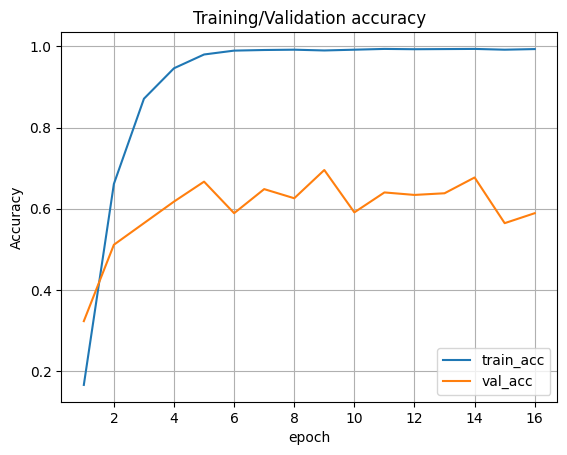

In [11]:
history_path=OUT_DIR/'training_history.csv'
if history_path.is_file():
    from IPython.display import display
    hist=pd.read_csv(history_path)
    display(hist.tail(12))
    ax=hist.plot(x='epoch',y=['train_acc','val_acc'],title='Training/Validation accuracy',grid=True)
    ax.set_ylabel('Accuracy')
    import matplotlib.pyplot as plt
    plt.show()
else:
    print('No full epoch has completed in this session.')